# NVIDIA BioClip2 — Crop Analysis

Runs **NVIDIA BioClip2** on every background-removed crop in `crops_nobg_matting`.

### Steps
1. Check GPU
2. Mount Google Drive
3. Install dependencies
4. Configure paths
5. Load BioClip2 model
6. Load crops
7. Zero-shot species classification
8. Embed all crops
9. HDBSCAN clustering
10. Visualize cluster grid
11. Save results to CSV

## 1 · Check GPU
Make sure you're on a GPU runtime: Runtime → Change runtime type → GPU.

In [1]:
!nvidia-smi

Wed May 20 02:16:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2 · Mount Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3 · Install Dependencies

In [3]:
!pip install -q open_clip_torch scikit-learn umap-learn dropbox

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 36.0 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.1/572.1 kB 42.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.3/162.3 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 kB 5.0 MB/s eta 0:00:00


## 4 · Configure Paths

Set `MISSION_CSV` to the mission-57 bounding-box CSV and `VIDEOS_DIR` to the folder containing the source `.mp4` files.

In [6]:
import os

DRIVE_ROOT  = '/content/drive/My Drive'

# ── Dropbox credentials ───────────────────────────────────────────────────────
DROPBOX_TOKEN     = 'sl.u.AGcEILqvX6e_ByZZptrJi8LL3OWUf5V5vwU-8mUg-dPfvluaI5ztBxjocmRcZe5GCkMXGz2mKqHvLLTMRDeZjt5w04Db5r8G3YFoTkZP1GwuWLtIGrkXIQ-sFP1DS4c0yVWQ5RKvHgJWKYiWitA6IfSnfyx4UbUgORMGsYkmedSjZU-4WFHkM07Ah9-ndILpJl62v0DP4KCSo82c6qyT_s1tEURdJnrf7gLuycpmdIDj-COkqUsNfh9J7pl4BTX3VuplIsjHwSlNPjrqCkaI4Bx6-1fGtic8wnqsW0HGqqDSTL9B-vx5iUzv-u0Fy5yNmadDA5kaVxok7092lOC32wWSUg-pyixQP1FJTH5hR3iWoL9P3T_0QLbrn54IGaR34jM_zV6VQ4n5_yOvS41CTwux9wwNL-Z39FsucMofasiagJdCrX0bx0vmrAmxAzTXmWhjWH-r1yzE0tJCEAInOPF20Kn6y-mAVNYu8PusCIOjImkHD7QNWsHsbkMGEIToeD5nVw_K5jgDph5mCdbiOVeq5uihc3DyxfRuhZROp9VwTij_ysmP7UaIAoMkD8Gasq8e5cV7tTfg0AmBIzhlAie-o9uo0MT3GU52E-Itlomzbgsy7H6Oz_kvIlHP3fO2mGIKDIboQAQ4PqiUide95M-ZdHWBhoFJBTFHBj7jE2njJpviO0gdiaM1u9ZEXHKkPqJpMyUrmx_l9MsOqe7j8UZt-ea64T4ox7Vy0sbBAQd3DGrdQILNFrkB2PHI4CfRbqzz-xQ0wwJP1DDQMkLUr3U7HLuPQByqzzXV5lQ9paT60NymT6eSEEAMtVhsXuyGtoE65ckEWvfl4xwFR7WR4Abu1jQeDCgtXKSwgxUisTdA1pLsglek6ouzuHGAOqMFlZbn0XSJkB7AfBE3icKYsotsyaffAaOaInYa4oHIHQ-rOhtEBq8S2VOF2_gOL_jwyWKoHjwxp78V7h1rzp4MEVB1VDDcoEoVXDi8duzVfCxioekNGA49IBk9_v0wPTrw8R_ZQdujHl2GYSbOh9-zJr0b0S-ma0e7NWlyPnpE3NFh3h8mbrT_tsyX8dkMaqZtVT_xQNaWE4_S3yIkcdskKGlZkg8V3Ux6LNw_i49mGiuY6q80jXmIayO05whUfSDK32z8RuPcMaHVyd7SYwc9gCIfWuOdqCpnoUqD-KKsrPqXx3jYb8N0wHwb7yaZCJAxU5bdELbCWRQO8i3YIUpboHjtruYblutCVMyMnoaN9QHveht3xGHhiZEblE_fSEo2vpWNnuT5xsgAajZ2ZFDgaL_mvPhwk6EA9a9ZWJfNOyUpvZCy21HG8aZw5bWTW5K4ECwMKLXVulxWutK25wqQdOvSpSxktu1Z5Q9S_HCdO7rv1vBEHkZXc4BP_rlbfmTDHw_Ssgi_zmanXVv_mYddkRyw0Vr_45_-37AbUVnCv6DsOw'
# paste your Dropbox access token
DROPBOX_BASE_PATH = '/DOEX0096_Palau'       # root folder in Dropbox

# ── Input: mission-57 bounding-box CSV (on Google Drive) ─────────────────────
MISSION_CSV = os.path.join(DRIVE_ROOT, 'mission_57.csv')

# ── Output: CSV with embeddings, species predictions, and cluster IDs ─────────
OUTPUT_DIR  = os.path.join(DRIVE_ROOT, 'output')
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Per-video outputs (one subfolder per video for sequential processing)
PER_VIDEO_OUTPUT_DIR = os.path.join(OUTPUT_DIR, 'per_video')
os.makedirs(PER_VIDEO_OUTPUT_DIR, exist_ok=True)

# ── BioClip2 inference settings ───────────────────────────────────────────────
BATCH_SIZE        = 32    # images per forward pass; lower if you hit OOM
TOP_K             = 20     # how many top species predictions to report
MIN_CLUSTER_SIZE  = 5     # HDBSCAN minimum cluster size

# ── Zero-shot candidate labels ────────────────────────────────────────────────
CANDIDATE_LABELS = [
    'fish', 'reef fish', 'tropical fish', 'shark', 'ray', 'manta ray',
    'stingray', 'jellyfish', 'octopus', 'squid', 'cuttlefish', 'crab',
    'lobster', 'shrimp', 'sea turtle', 'eel', 'moray eel', 'starfish',
    'sea urchin', 'coral', 'sea anemone', 'nudibranch', 'seahorse',
    'clownfish', 'parrotfish', 'grouper', 'tuna', 'barracuda',
]

print('Config OK')
print(f'Mission CSV: {MISSION_CSV}')
print(f'Output dir : {OUTPUT_DIR}')

Config OK
Mission CSV: /content/drive/My Drive/mission_57.csv
Output dir : /content/drive/My Drive/output


## 4b · Connect to Dropbox

In [7]:
import dropbox

dbx = dropbox.Dropbox(DROPBOX_TOKEN)

try:
    dbx.users_get_current_account()
    print('Dropbox connection OK')
    
    for entry in dbx.files_list_folder('/DOEX0096_Palau').entries:
        print(entry.name)
  
except dropbox.exceptions.AuthError:
    raise RuntimeError('Dropbox auth failed — check your DROPBOX_TOKEN.')

Dropbox connection OK
PLW_dscm_01
PLW_dscm_02
PLW_dscm_03
PLW_dscm_04
PLW_dscm_05
PLW_dscm_06
PLW_dscm_07
PLW_dscm_08
PLW_dscm_32
PLW_dscm_33
PLW_dscm_34
PLW_dscm_09
PLW_dscm_35
PLW_dscm_10
PLW_dscm_11
PLW_dscm_12
PLW_dscm_13
PLW_dscm_14
PLW_dscm_15
PLW_dscm_16
PLW_dscm_17
PLW_dscm_18
PLW_dscm_19
PLW_dscm_20
PLW_dscm_21
PLW_dscm_22
PLW_dscm_23
PLW_dscm_24
PLW_dscm_25
PLW_dscm_26
PLW_dscm_27
PLW_dscm_28
PLW_dscm_29
PLW_dscm_30
PLW_dscm_31
PLW_dscm_36
PLW_dscm_37
PLW_dscm_38
PLW_dscm_39
PLW_dscm_40
PLW_dscm_41
PLW_dscm_42
PLW_dscm_43
PLW_dscm_44
PLW_dscm_45
PLW_dscm_46
PLW_dscm_47
PLW_dscm_48
PLW_dscm_49
PLW_dscm_50
PLW_dscm_51
PLW_dscm_52
PLW_dscm_53
PLW_dscm_54
PLW_dscm_55
PLW_dscm_57
PLW_dscm_58
PLW_dscm_56
PLW_2024_dscm_fieldbook.xlsx


## 5 · Load NVIDIA BioClip2

In [8]:
import open_clip
import torch

BIOCLIP_MODEL = 'hf-hub:imageomics/bioclip'

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {device}')

model, preprocess_train, preprocess_val = open_clip.create_model_and_transforms(BIOCLIP_MODEL)
tokenizer = open_clip.get_tokenizer(BIOCLIP_MODEL)
model = model.to(device).eval()

print(f'BioCLIP loaded: {BIOCLIP_MODEL}')

Device: cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:103: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


open_clip_config.json:   0%|          | 0.00/469 [00:00<?, ?B/s]

open_clip_pytorch_model.bin:   0%|          | 0.00/599M [00:00<?, ?B/s]

BioCLIP loaded: hf-hub:imageomics/bioclip


## 6 · Sequential per-video pipeline

Instead of extracting **all** crops from **all** videos and then running embedding +
clustering globally, this version walks one video at a time:

1. Load the mission CSV and group detections by `media_id`.
2. For each video:
   - Extract its crops (highest-confidence detection per track)
   - Background-remove them with BiRefNet
   - Embed with BioClip2 + zero-shot species classification
   - Cluster (HDBSCAN, KMeans fallback) **using only that video's embeddings**
   - Save a per-video predictions CSV and show its cluster grid
3. After the loop, merge all per-video CSVs into one combined file. Cluster IDs are
   namespaced as `{video_stem}::{local_cluster_id}` so they don't collide across videos.

**Why sequential?** Memory stays bounded (only one video's crops in RAM at a time),
you get per-video clustering that isn't dominated by whichever video has the most
detections, and you can interrupt/resume between videos.


### 6a · Load mission CSV and helpers


In [9]:
import os
import tempfile
import urllib.request
import cv2
import numpy as np
import pandas as pd
from PIL import Image

# ── Load bounding-box CSV ─────────────────────────────────────────────────────
bbox_df = pd.read_csv(MISSION_CSV)
print(f'Loaded {len(bbox_df):,} detections across {bbox_df["media_id"].nunique()} video(s)')

# Per track: keep only the highest-confidence detection
best = (
    bbox_df
    .sort_values('confidence', ascending=False)
    .drop_duplicates(subset=['media_id', 'track_id'])
    .reset_index(drop=True)
)
print(f'Unique tracks: {len(best)}')

# Group tracks by video so we can iterate one video at a time
videos = sorted(best['media_id'].unique())
print(f'Videos to process: {len(videos)}')
for v in videos:
    print(f'  {v}: {(best["media_id"] == v).sum()} tracks')

# Local video cache (one mp4 at a time — we delete after processing to save disk)
VIDEO_CACHE = tempfile.mkdtemp(prefix='bioclip_videos_')


def deployment_from_media_id(media_id):
    """'PLW_dscm_57_c002.mp4' → 'PLW_dscm_57'."""
    stem  = os.path.splitext(media_id)[0]
    parts = stem.rsplit('_', 1)
    if len(parts) == 2 and parts[1].startswith('c') and parts[1][1:].isdigit():
        return parts[0]
    return stem


def fetch_video(video_name):
    local_path = os.path.join(VIDEO_CACHE, video_name)
    if os.path.exists(local_path) and os.path.getsize(local_path) > 0:
        return local_path
    deployment   = deployment_from_media_id(video_name)
    dropbox_path = f'{DROPBOX_BASE_PATH}/{deployment}/Video/{video_name}'
    try:
        link = dbx.files_get_temporary_link(dropbox_path)
        urllib.request.urlretrieve(link.link, local_path)
        return local_path
    except Exception as e:
        print(f'  WARNING: could not fetch {dropbox_path}: {e}')
        return None


def extract_crops_for_video(video_name, tracks_df, crop_dir):
    """Extract one crop per track for a single video.

    Returns a list of (PIL.Image, metadata dict). Crops are also saved as PNGs
    to ``crop_dir`` for resumability.
    """
    os.makedirs(crop_dir, exist_ok=True)

    local_path = fetch_video(video_name)
    if local_path is None:
        return []

    cap = cv2.VideoCapture(local_path)
    if not cap.isOpened():
        print(f'  WARNING: could not open {video_name}')
        return []

    vid_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    vid_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    crops = []
    for _, row in tracks_df.iterrows():
        track_id  = int(row['track_id'])
        crop_name = f'{os.path.splitext(video_name)[0]}__id{track_id:06d}.png'
        crop_path = os.path.join(crop_dir, crop_name)

        # Resume support: reuse existing crop file
        if os.path.exists(crop_path):
            img = Image.open(crop_path).convert('RGB')
            crops.append((img, {
                'media_id'  : video_name,
                'track_id'  : track_id,
                'frame'     : int(row['frame']),
                'confidence': float(row['confidence']),
                'crop_file' : crop_name,
            }))
            continue

        cap.set(cv2.CAP_PROP_POS_FRAMES, int(row['frame']))
        ret, frame_bgr = cap.read()
        if not ret:
            continue

        x1 = max(0,     int(row['x']                  * vid_w))
        y1 = max(0,     int(row['y']                  * vid_h))
        x2 = min(vid_w, int((row['x'] + row['width']) * vid_w))
        y2 = min(vid_h, int((row['y'] + row['height']) * vid_h))
        if x2 <= x1 or y2 <= y1:
            continue

        crop_rgb = cv2.cvtColor(frame_bgr[y1:y2, x1:x2], cv2.COLOR_BGR2RGB)
        img = Image.fromarray(crop_rgb)
        img.save(crop_path)

        crops.append((img, {
            'media_id'  : video_name,
            'track_id'  : track_id,
            'frame'     : int(row['frame']),
            'confidence': float(row['confidence']),
            'x1': x1, 'y1': y1, 'x2': x2, 'y2': y2,
            'crop_file' : crop_name,
        }))

    cap.release()
    return crops


Loaded 474,647 detections across 225 video(s)
Unique tracks: 5601
Videos to process: 225
  PLW_dscm_57_c002.mp4: 4 tracks
  PLW_dscm_57_c008.mp4: 2 tracks
  PLW_dscm_57_c009.mp4: 16 tracks
  PLW_dscm_57_c010.mp4: 15 tracks
  PLW_dscm_57_c011.mp4: 2 tracks
  PLW_dscm_57_c012.mp4: 14 tracks
  PLW_dscm_57_c013.mp4: 6 tracks
  PLW_dscm_57_c014.mp4: 4 tracks
  PLW_dscm_57_c015.mp4: 3 tracks
  PLW_dscm_57_c016.mp4: 7 tracks
  PLW_dscm_57_c017.mp4: 6 tracks
  PLW_dscm_57_c018.mp4: 16 tracks
  PLW_dscm_57_c019.mp4: 22 tracks
  PLW_dscm_57_c020.mp4: 28 tracks
  PLW_dscm_57_c021.mp4: 12 tracks
  PLW_dscm_57_c022.mp4: 32 tracks
  PLW_dscm_57_c023.mp4: 26 tracks
  PLW_dscm_57_c024.mp4: 32 tracks
  PLW_dscm_57_c025.mp4: 49 tracks
  PLW_dscm_57_c026.mp4: 50 tracks
  PLW_dscm_57_c027.mp4: 26 tracks
  PLW_dscm_57_c028.mp4: 24 tracks
  PLW_dscm_57_c029.mp4: 22 tracks
  PLW_dscm_57_c030.mp4: 29 tracks
  PLW_dscm_57_c031.mp4: 29 tracks
  PLW_dscm_57_c032.mp4: 32 tracks
  PLW_dscm_57_c033.mp4: 45 tracks
 

### 6b · Background removal helper (BiRefNet)

We build the rembg session **once** outside the loop so we don't reload model weights for every video.


In [10]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rembg[gpu]"], check=True)

from rembg import remove, new_session

# BiRefNet — best quality for fine animal edges; falls back to u2net on CPU
try:
    bg_session = new_session("birefnet-general")
    print('Using BiRefNet session')
except Exception:
    bg_session = new_session("u2net")
    print('Fell back to u2net session')


def remove_background(pil_img):
    """Remove background with rembg/BiRefNet, feather the edge, return RGBA."""
    result_rgba = remove(pil_img.convert('RGB'), session=bg_session)
    w_crop, h_crop = pil_img.size

    alpha_raw = np.array(result_rgba)[:, :, 3]
    alpha_mask = cv2.resize(
        alpha_raw.astype(np.float32),
        (w_crop, h_crop),
        interpolation=cv2.INTER_LANCZOS4,
    )
    alpha_mask = np.clip(alpha_mask, 0, 255).astype(np.uint8)

    # Feather edge
    alpha_f    = cv2.GaussianBlur(alpha_mask.astype(np.float32), (3, 3), sigmaX=0.8)
    alpha_mask = np.clip(alpha_f, 0, 255).astype(np.uint8)

    rgba = pil_img.convert('RGBA')
    rgba.putalpha(Image.fromarray(alpha_mask))
    return rgba


  0%|                                               | 0.00/973M [00:00<?, ?B/s]

Using BiRefNet session


### 6c · Embedding + zero-shot classification helper

Text embeddings for the candidate species labels are computed once and reused.


In [11]:
# ── Encode text labels once (reused for every video) ─────────────────────────
prompts = [f'a photo of a {label}' for label in CANDIDATE_LABELS]
text_tokens = tokenizer(prompts).to(device)

with torch.no_grad():
    text_features = model.encode_text(text_tokens)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)

print(f'Text features: {text_features.shape}  ({len(CANDIDATE_LABELS)} labels)')


def embed_and_classify(pil_images):
    """Run BioClip2 on a list of PIL images.

    Returns (embeddings [N, D], probs [N, n_labels]) as numpy arrays.
    """
    all_feats = []
    all_probs = []
    for start in range(0, len(pil_images), BATCH_SIZE):
        batch   = pil_images[start : start + BATCH_SIZE]
        tensors = torch.stack([preprocess_val(img) for img in batch]).to(device)

        with torch.no_grad():
            img_feats = model.encode_image(tensors)
            img_feats = img_feats / img_feats.norm(dim=-1, keepdim=True)

        logit_scale = model.logit_scale.exp()
        logits      = logit_scale * img_feats @ text_features.T
        probs       = logits.softmax(dim=-1).detach().cpu().float().numpy()

        all_feats.append(img_feats.cpu().float().numpy())
        all_probs.append(probs)

    return np.vstack(all_feats), np.vstack(all_probs)


Text features: torch.Size([28, 512])  (28 labels)


### 6d · Clustering helper

Same HDBSCAN-with-KMeans-fallback logic as before, but parameterised so we can call it on each video's embeddings.


In [12]:
from sklearn.cluster import HDBSCAN, KMeans


def cluster_embeddings(embs, min_cluster_size=MIN_CLUSTER_SIZE):
    """Return (cluster_labels, n_clusters, n_noise, method).

    Falls back to KMeans when HDBSCAN finds fewer than 2 clusters or when there
    are too few points for HDBSCAN to be meaningful.
    """
    n = len(embs)
    if n < 2:
        # Single point — trivially one cluster
        return np.zeros(n, dtype=int), 1 if n == 1 else 0, 0, 'trivial'

    # HDBSCAN needs at least min_cluster_size points to find anything
    if n >= min_cluster_size:
        labels = HDBSCAN(
            min_cluster_size=min_cluster_size,
            min_samples=min(3, max(1, n // 3)),
            metric='cosine',
            cluster_selection_method='eom',
        ).fit_predict(embs)

        n_clusters = len(set(labels) - {-1})
        n_noise    = int((labels == -1).sum())

        if n_clusters >= 2:
            return labels, n_clusters, n_noise, 'hdbscan'

    # Fallback: KMeans with a heuristic k
    k = max(2, min(int(np.sqrt(n / 2)), n))
    labels = KMeans(n_clusters=k, random_state=42, n_init='auto').fit_predict(embs)
    return labels, k, 0, f'kmeans(k={k})'


## 7 · Run the per-video pipeline

For each video, this cell prints a header, extracts crops, removes backgrounds,
embeds, classifies, clusters, and saves a per-video predictions CSV.

Per-video artifacts written to `OUTPUT_DIR/per_video/<video_stem>/`:
- `crops/` — raw RGB crops (resume-friendly)
- `crops_nobg/` — RGBA crops with background removed
- `predictions.csv` — per-track predictions + local cluster ID
- `embeddings.npy` — embedding matrix (for later re-clustering if you want)
- `cluster_grid.png` / `cluster_thumbs/` — visualisations



 Video 1/225: PLW_dscm_57_c002.mp4 
  Extracting 4 crops...
  Got 4 crops
  Removing backgrounds...
  Background removal done (4 crops)
  Embedding + classifying...
  Embeddings: (4, 512)
  Clustering...


Exception ignored on calling ctypes callback function: <function ThreadpoolController._find_libraries_with_dl_iterate_phdr.<locals>.match_library_callback at 0x780048fbede0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/threadpoolctl.py", line 1005, in match_library_callback
    self._make_controller_from_path(filepath)
  File "/usr/local/lib/python3.12/dist-packages/threadpoolctl.py", line 1187, in _make_controller_from_path
    lib_controller = controller_class(
                     ^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/threadpoolctl.py", line 114, in __init__
    self.dynlib = ctypes.CDLL(filepath, mode=_RTLD_NOLOAD)
                  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/ctypes/__init__.py", line 379, in __init__
    self._handle = _dlopen(self._name, mode)
                   ^^^^^^^^^^^^^^^^^^^^^^^^^
OSError: /usr/local/lib/python3.12/dist-packages/numpy.libs/libscipy_openblas64_-99b71e

  Clusters: 2  Noise: 0  (kmeans(k=2))
  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c002/predictions.csv


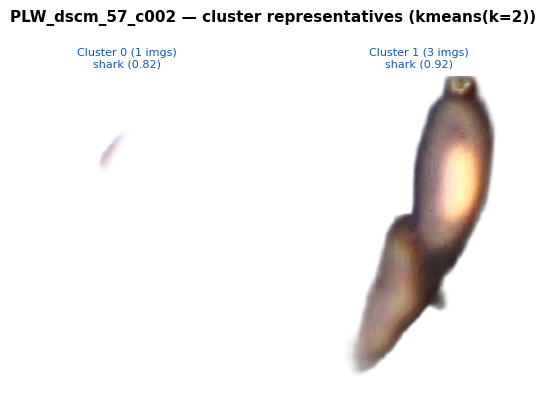

  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c002/cluster_grid.png

 Video 2/225: PLW_dscm_57_c008.mp4 
  Extracting 2 crops...
  Got 2 crops
  Removing backgrounds...
  Background removal done (2 crops)
  Embedding + classifying...
  Embeddings: (2, 512)
  Clustering...
  Clusters: 2  Noise: 0  (kmeans(k=2))
  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c008/predictions.csv


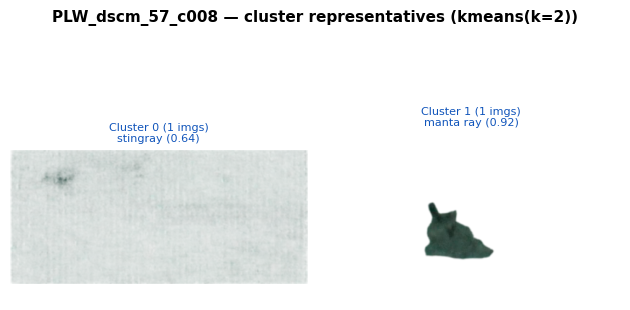

  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c008/cluster_grid.png

 Video 3/225: PLW_dscm_57_c009.mp4 
  Extracting 16 crops...
  Got 16 crops
  Removing backgrounds...
  Background removal done (16 crops)
  Embedding + classifying...
  Embeddings: (16, 512)
  Clustering...
  Clusters: 2  Noise: 2  (hdbscan)
  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c009/predictions.csv


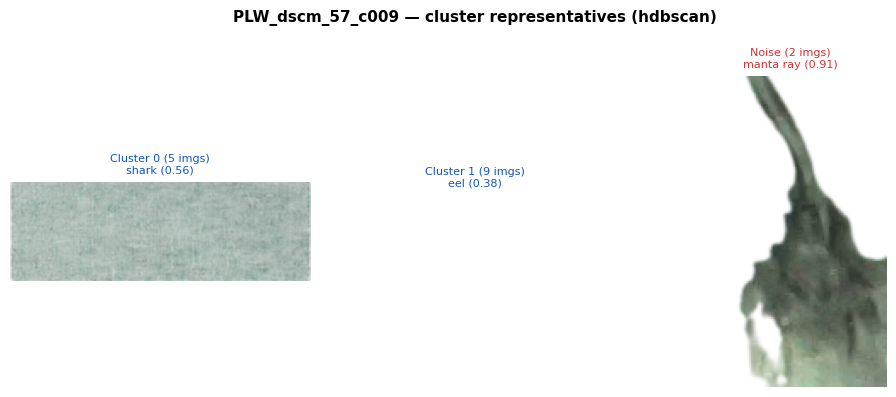

  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c009/cluster_grid.png

 Video 4/225: PLW_dscm_57_c010.mp4 
  Extracting 15 crops...
  Got 15 crops
  Removing backgrounds...
  Background removal done (15 crops)
  Embedding + classifying...
  Embeddings: (15, 512)
  Clustering...
  Clusters: 2  Noise: 1  (hdbscan)
  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c010/predictions.csv


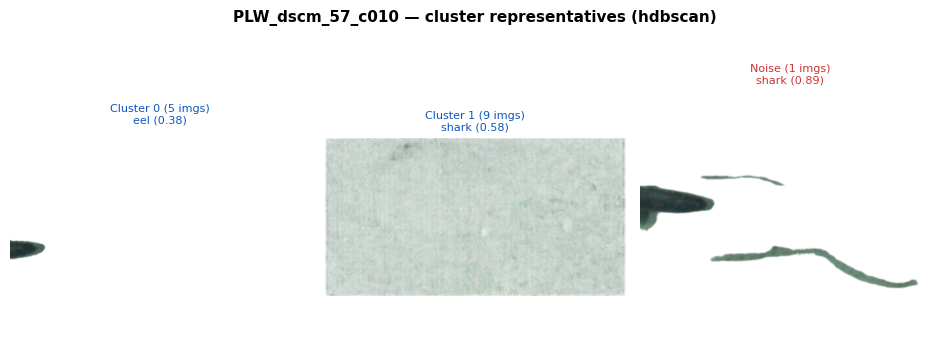

  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c010/cluster_grid.png

 Video 5/225: PLW_dscm_57_c011.mp4 
  Extracting 2 crops...
  Got 2 crops
  Removing backgrounds...
  Background removal done (2 crops)
  Embedding + classifying...
  Embeddings: (2, 512)
  Clustering...
  Clusters: 2  Noise: 0  (kmeans(k=2))
  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c011/predictions.csv


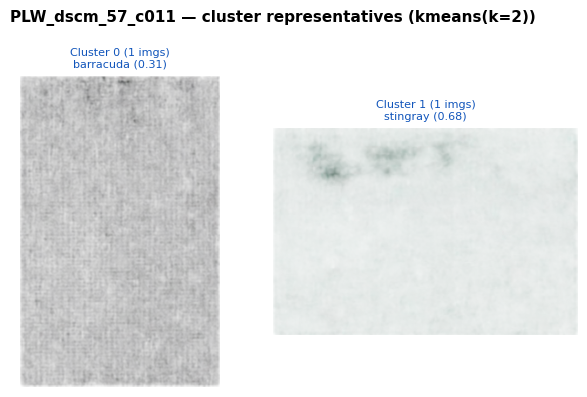

  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c011/cluster_grid.png

 Video 6/225: PLW_dscm_57_c012.mp4 
  Extracting 14 crops...
  Got 14 crops
  Removing backgrounds...
  Background removal done (14 crops)
  Embedding + classifying...
  Embeddings: (14, 512)
  Clustering...
  Clusters: 2  Noise: 0  (kmeans(k=2))
  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c012/predictions.csv


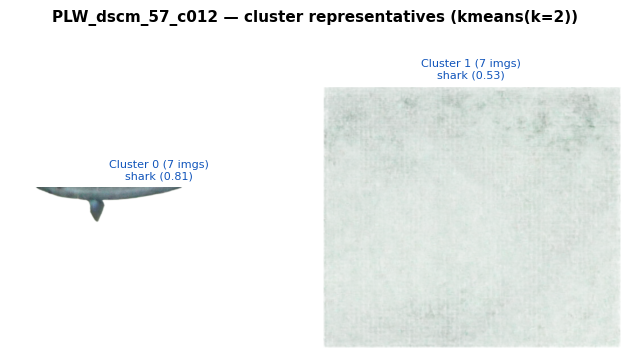

  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c012/cluster_grid.png

 Video 7/225: PLW_dscm_57_c013.mp4 
  Extracting 6 crops...
  Got 6 crops
  Removing backgrounds...
  Background removal done (6 crops)
  Embedding + classifying...
  Embeddings: (6, 512)
  Clustering...
  Clusters: 2  Noise: 0  (kmeans(k=2))
  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c013/predictions.csv


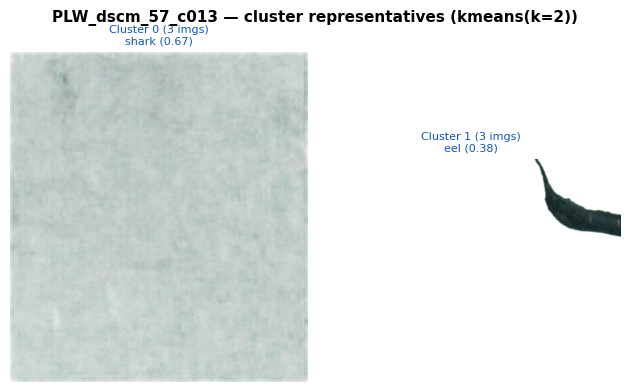

  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c013/cluster_grid.png

 Video 8/225: PLW_dscm_57_c014.mp4 
  Extracting 4 crops...
  Got 4 crops
  Removing backgrounds...
  Background removal done (4 crops)
  Embedding + classifying...
  Embeddings: (4, 512)
  Clustering...
  Clusters: 2  Noise: 0  (kmeans(k=2))
  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c014/predictions.csv


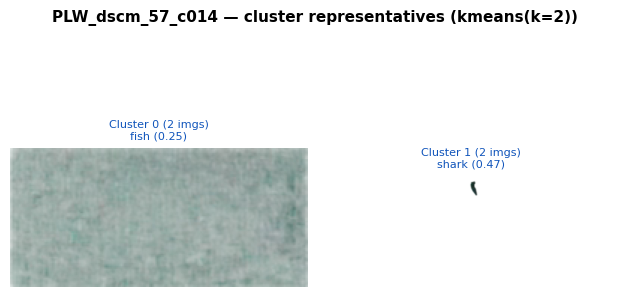

  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c014/cluster_grid.png

 Video 9/225: PLW_dscm_57_c015.mp4 
  Extracting 3 crops...
  Got 3 crops
  Removing backgrounds...
  Background removal done (3 crops)
  Embedding + classifying...
  Embeddings: (3, 512)
  Clustering...
  Clusters: 2  Noise: 0  (kmeans(k=2))
  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c015/predictions.csv


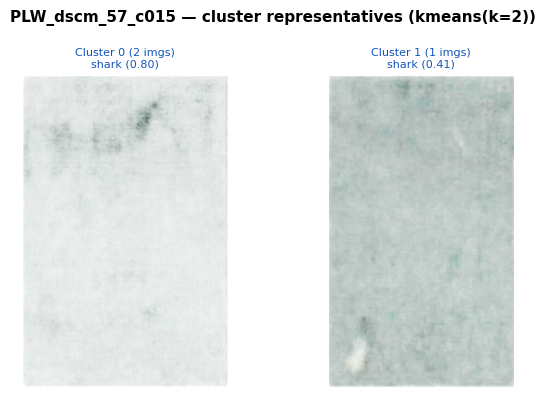

  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c015/cluster_grid.png

 Video 10/225: PLW_dscm_57_c016.mp4 
  Extracting 7 crops...
  Got 7 crops
  Removing backgrounds...
  Background removal done (7 crops)
  Embedding + classifying...
  Embeddings: (7, 512)
  Clustering...
  Clusters: 2  Noise: 0  (kmeans(k=2))
  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c016/predictions.csv


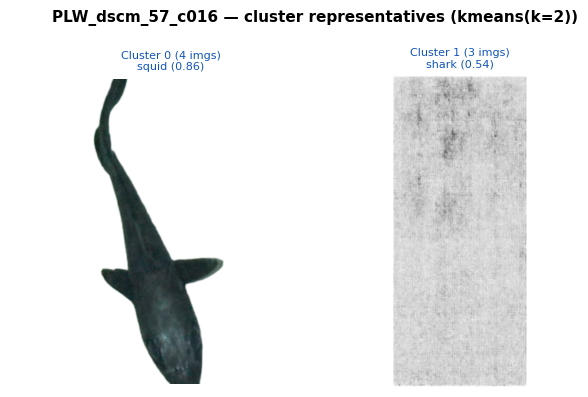

  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c016/cluster_grid.png

 Video 11/225: PLW_dscm_57_c017.mp4 
  Extracting 6 crops...
  Got 6 crops
  Removing backgrounds...
  Background removal done (6 crops)
  Embedding + classifying...
  Embeddings: (6, 512)
  Clustering...
  Clusters: 2  Noise: 0  (kmeans(k=2))
  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c017/predictions.csv


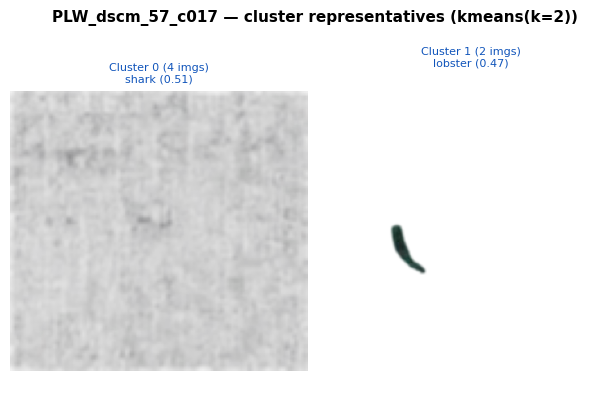

  Saved /content/drive/My Drive/output/per_video/PLW_dscm_57_c017/cluster_grid.png

 Video 12/225: PLW_dscm_57_c018.mp4 
  Extracting 16 crops...


In [ ]:
import matplotlib.pyplot as plt
import gc

# Aggregate across videos for the final combined CSV
all_video_records = []

for video_idx, video_name in enumerate(videos, start=1):
    video_stem = os.path.splitext(video_name)[0]
    video_dir  = os.path.join(PER_VIDEO_OUTPUT_DIR, video_stem)
    crops_dir  = os.path.join(video_dir, 'crops')
    nobg_dir   = os.path.join(video_dir, 'crops_nobg')
    thumbs_dir = os.path.join(video_dir, 'cluster_thumbs')
    pred_csv   = os.path.join(video_dir, 'predictions.csv')
    emb_npy    = os.path.join(video_dir, 'embeddings.npy')

    os.makedirs(video_dir,  exist_ok=True)
    os.makedirs(nobg_dir,   exist_ok=True)
    os.makedirs(thumbs_dir, exist_ok=True)

    header = f' Video {video_idx}/{len(videos)}: {video_name} '
    print(f'\n{"=" * len(header)}')
    print(header)
    print(f'{"=" * len(header)}')

    # Resume support: skip videos whose predictions.csv already exists
    if os.path.exists(pred_csv):
        print(f'  ✓ Already done — loading existing predictions.csv')
        existing = pd.read_csv(pred_csv)
        all_video_records.append(existing)
        continue

    # 1. Extract crops for this video
    video_tracks = best[best['media_id'] == video_name]
    print(f'  Extracting {len(video_tracks)} crops...', flush=True)
    crops = extract_crops_for_video(video_name, video_tracks, crops_dir)
    if not crops:
        print(f'  No crops extracted — skipping video')
        continue
    pil_raw, meta_list = zip(*crops)
    pil_raw  = list(pil_raw)
    meta_list = list(meta_list)
    print(f'  Got {len(pil_raw)} crops')

    # 2. Background removal
    print(f'  Removing backgrounds...', flush=True)
    pil_nobg = []
    for i, img in enumerate(pil_raw):
        try:
            rgba = remove_background(img)
        except Exception as e:
            print(f'    WARNING: crop {i} bg-removal failed ({e}); using original')
            rgba = img.convert('RGBA')
        pil_nobg.append(rgba)
        # Persist for later inspection
        rgba.save(os.path.join(nobg_dir, meta_list[i]['crop_file']))
    print(f'  Background removal done ({len(pil_nobg)} crops)')

    # 3. Embed + zero-shot classification
    print(f'  Embedding + classifying...', flush=True)
    embeddings, probs = embed_and_classify(pil_nobg)
    np.save(emb_npy, embeddings)
    print(f'  Embeddings: {embeddings.shape}')

    # 4. Cluster (per-video)
    print(f'  Clustering...', flush=True)
    cluster_labels, n_clusters, n_noise, method = cluster_embeddings(embeddings)
    print(f'  Clusters: {n_clusters}  Noise: {n_noise}  ({method})')

    # 5. Build per-video predictions table
    records = []
    for i, meta in enumerate(meta_list):
        top_k_idx  = probs[i].argsort()[::-1][:TOP_K]
        top_labels = [CANDIDATE_LABELS[j] for j in top_k_idx]
        top_scores = [float(probs[i][j])  for j in top_k_idx]

        rec = {
            'media_id'      : meta['media_id'],
            'track_id'      : meta['track_id'],
            'frame'         : meta['frame'],
            'confidence'    : meta['confidence'],
            'cluster_id'    : int(cluster_labels[i]),
            'cluster_method': method,
        }
        for rank, (lbl, score) in enumerate(zip(top_labels, top_scores), start=1):
            rec[f'top{rank}_label'] = lbl
            rec[f'top{rank}_score'] = round(score, 4)
        records.append(rec)

    preds_df = pd.DataFrame(records)
    preds_df.to_csv(pred_csv, index=False)
    print(f'  Saved {pred_csv}')

    # 6. Cluster grid for this video (representative per cluster)
    def _rep_idx(mask):
        e = embeddings[mask]
        centroid = e.mean(axis=0, keepdims=True)
        local = int(np.argmin(np.linalg.norm(e - centroid, axis=1)))
        return np.where(mask)[0][local]

    unique_clusters = sorted(set(cluster_labels))
    plot_lbls = [l for l in unique_clusters if l >= 0] + ([-1] if -1 in unique_clusters else [])
    if plot_lbls:
        n_cols = min(6, len(plot_lbls))
        n_rows = max(1, (len(plot_lbls) + n_cols - 1) // n_cols)
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 4 * n_rows), squeeze=False)
        axes_flat = axes.flatten()
        for ax_idx, lbl in enumerate(plot_lbls):
            mask    = cluster_labels == lbl
            rep_idx = _rep_idx(mask)
            axes_flat[ax_idx].imshow(pil_nobg[rep_idx])
            top1  = preds_df.iloc[rep_idx]['top1_label']
            score = preds_df.iloc[rep_idx]['top1_score']
            count = int(mask.sum())
            if lbl == -1:
                title = f'Noise ({count} imgs)\n{top1} ({score:.2f})'
                color = '#cc3333'
            else:
                title = f'Cluster {lbl} ({count} imgs)\n{top1} ({score:.2f})'
                color = '#1155bb'
            axes_flat[ax_idx].set_title(title, fontsize=8, color=color)
            axes_flat[ax_idx].axis('off')
        for ax in axes_flat[len(plot_lbls):]:
            ax.axis('off')
        plt.suptitle(f'{video_stem} — cluster representatives ({method})',
                     fontsize=11, fontweight='bold')
        plt.tight_layout()
        grid_path = os.path.join(video_dir, 'cluster_grid.png')
        plt.savefig(grid_path, dpi=110, bbox_inches='tight')
        plt.show()
        plt.close(fig)
        print(f'  Saved {grid_path}')

    all_video_records.append(preds_df)

    # 7. Clean up this video's heavy in-memory data + delete cached mp4
    cached = os.path.join(VIDEO_CACHE, video_name)
    if os.path.exists(cached):
        try:
            os.remove(cached)
        except OSError:
            pass
    del pil_raw, pil_nobg, embeddings, probs, cluster_labels, meta_list, crops
    gc.collect()
    try:
        torch.cuda.empty_cache()
    except Exception:
        pass

print(f'\n✓ All {len(videos)} videos processed.')


## 8 · Merge per-video results into one combined CSV

Cluster IDs from different videos are **not comparable** (cluster 0 in video A is
unrelated to cluster 0 in video B), so we add a globally-unique `video_cluster_id`
column of the form `<video_stem>::<local_id>`. The original `cluster_id` column is
preserved so you can still group within a single video.


In [ ]:
if all_video_records:
    combined = pd.concat(all_video_records, ignore_index=True)

    # Namespace cluster IDs so they don't collide across videos
    combined['video_stem'] = combined['media_id'].apply(lambda m: os.path.splitext(m)[0])
    combined['video_cluster_id'] = (
        combined['video_stem'] + '::' + combined['cluster_id'].astype(str)
    )

    # Reorder columns
    front = ['media_id', 'video_stem', 'track_id', 'frame', 'confidence',
             'cluster_id', 'video_cluster_id', 'cluster_method',
             'top1_label', 'top1_score']
    rest  = [c for c in combined.columns if c not in front]
    combined = combined[[c for c in front if c in combined.columns] + rest]

    combined_csv = os.path.join(OUTPUT_DIR, 'bioclip2_predictions_per_video.csv')
    combined.to_csv(combined_csv, index=False)
    print(f'Saved combined CSV: {combined_csv}')
    print(f'Total crops across all videos: {len(combined)}')

    from IPython.display import display
    display(combined.head(20))
else:
    print('No per-video records to merge.')
    combined = pd.DataFrame()


## 9 · Summary stats across videos


In [ ]:
if len(combined):
    print('=== BioClip2 Sequential Run Summary ===')
    print(f'Videos processed     : {combined["media_id"].nunique()}')
    print(f'Total crops analysed : {len(combined)}')
    print()

    print('--- Crops + clusters per video ---')
    per_video = (
        combined.groupby('media_id')
        .agg(n_crops=('track_id', 'count'),
             n_clusters=('cluster_id', lambda s: len(set(s) - {-1})),
             n_noise=('cluster_id', lambda s: int((s == -1).sum())))
    )
    print(per_video.to_string())
    print()

    print('--- Top-1 label distribution (across all videos) ---')
    print(combined['top1_label'].value_counts().to_string())
else:
    print('No results to summarise.')
